# 01 — Data preparation, descriptive statistics and A-Priori

Run top to bottom after putting the six CSVs in `data/` (see README).

1. The six files and how they connect, with integrity checks
2. Descriptive statistics
3. Baskets: one order = the set of its unique product ids, read in chunks and cached
4. The next-basket task and the train / validation / test split of users
5. Our own **A-Priori** for frequent pairs: a hand-checkable toy example, a brute-force check, and the full data
6. Extension: frequent triples (a third A-Priori pass)

Needs ~2 GB RAM, ~2 minutes.

In [1]:
import sys, time
from collections import Counter
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))
from src.data import Baskets, load_tables, load_baskets, to_baskets, next_basket_truth, user_split
from src.apriori import apriori_pairs, apriori_triples, association_rules
from src.pcy import apriori_memory_mb

ROOT = Path.cwd().parent
FIG_DIR = ROOT / "figures"
DERIVED = ROOT / "data" / "derived"
DERIVED.mkdir(exist_ok=True)

## 1. The six files and how they connect

| file | one row per | key columns | role |
|---|---|---|---|
| `orders.csv` | order | `order_id`, `user_id`, `order_number`, `eval_set` | which user placed each order, in which sequence and timing; `eval_set` says which split the order belongs to |
| `order_products__prior.csv` | (order, product) | `order_id` → orders, `product_id` → products | contents of every *prior* order: the purchase history |
| `order_products__train.csv` | (order, product) | same | contents of each user's *last* order, for 131k users: our held-out ground truth |
| `products.csv` | product | `product_id`, `aisle_id`, `department_id` | product names and category labels |
| `aisles.csv`, `departments.csv` | aisle / department | `aisle_id` / `department_id` | category names |

The remaining 75k users' last orders are `test` in Kaggle's competition; their contents are not published, so we cannot use those users as ground truth.

In [2]:
t = time.time()
tables = load_tables()
orders, prior, train, products = (tables[k] for k in ("orders", "prior", "train", "products"))
name = products.set_index("product_id")["product_name"]
print(f"loaded in {time.time() - t:.1f}s")
for k, df in tables.items():
    print(f"{k:9s} {len(df):>12,} rows  {df.memory_usage(deep=True).sum() / 1e6:8.1f} MB")

loaded in 3.6s
orders       3,421,083 rows      58.2 MB
prior       32,434,489 rows     356.8 MB
train        1,384,617 rows      15.2 MB
products        49,688 rows      12.4 MB


In [3]:
# Integrity checks: every assumption the rest of the project relies on
assert orders["order_id"].is_unique
eval_set = orders.set_index("order_id")["eval_set"]
assert (eval_set.reindex(prior["order_id"].unique()) == "prior").all(), "prior rows must belong to prior orders"
assert (eval_set.reindex(train["order_id"].unique()) == "train").all(), "train rows must belong to train orders"
assert prior["product_id"].isin(products["product_id"]).all() and train["product_id"].isin(products["product_id"]).all()
assert not prior.duplicated(["order_id", "product_id"]).any(), "a product appears at most once per order"

last = orders.sort_values("order_number").groupby("user_id").tail(1)
assert last["eval_set"].isin(["train", "test"]).all(), "each user's last order is their train or test order"
assert (orders["eval_set"] != "prior").groupby(orders["user_id"]).sum().eq(1).all(), "exactly one non-prior order per user"
assert orders.loc[orders["order_number"] == 1, "days_since_prior_order"].isna().all()
print("all integrity checks passed")

all integrity checks passed


## 2. Descriptive statistics

In [4]:
print(f"users    {orders['user_id'].nunique():,}")
print(f"orders   {len(orders):,}")
print(f"products {len(products):,} in {products['aisle_id'].nunique()} aisles / {products['department_id'].nunique()} departments")
print(f"products ever bought in a prior order: {prior['product_id'].nunique():,}")
print(orders["eval_set"].value_counts().to_string())
print(f"prior orders per user: median {orders[orders['eval_set'] == 'prior'].groupby('user_id').size().median():.0f}, "
      f"min {orders[orders['eval_set'] == 'prior'].groupby('user_id').size().min()}, max {orders[orders['eval_set'] == 'prior'].groupby('user_id').size().max()}")
print(f"reorder rate in prior orders: {prior['reordered'].mean():.1%}")

users    206,209
orders   3,421,083
products 49,688 in 134 aisles / 21 departments
products ever bought in a prior order: 49,677
eval_set
prior    3214874
train     131209
test       75000


prior orders per user: median 9, min 3, max 99
reorder rate in prior orders: 59.0%


basket size: mean 10.1, median 8, max 145
basket size percentiles 10/25/50/75/90/99%: [ 2  5  8 14 20 35]


,product,orders,share of baskets
0,Banana,472565,0.147
1,Bag of Organic Bananas,379450,0.118
2,Organic Strawberries,264683,0.082
3,Organic Baby Spinach,241921,0.075
4,Organic Hass Avocado,213584,0.066
5,Organic Avocado,176815,0.055
6,Large Lemon,152657,0.047
7,Strawberries,142951,0.044
8,Limes,140627,0.044
9,Organic Whole Milk,137905,0.043


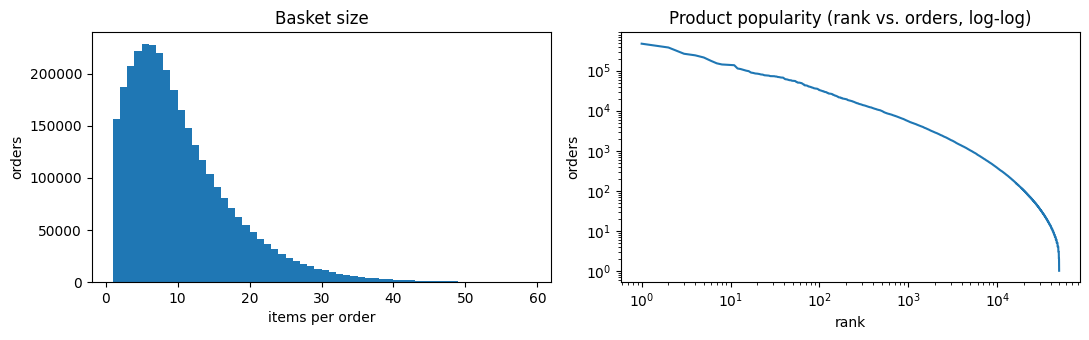

In [5]:
sizes = prior.groupby("order_id").size()
counts = prior["product_id"].value_counts()

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(sizes, bins=range(1, 60))
ax[0].set(title="Basket size", xlabel="items per order", ylabel="orders")
ax[1].loglog(np.arange(1, len(counts) + 1), counts.to_numpy())
ax[1].set(title="Product popularity (rank vs. orders, log-log)", xlabel="rank", ylabel="orders")
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_sizes_popularity.png", dpi=150)
print(f"basket size: mean {sizes.mean():.1f}, median {sizes.median():.0f}, max {sizes.max()}")
print("basket size percentiles 10/25/50/75/90/99%:", np.percentile(sizes, [10, 25, 50, 75, 90, 99]).astype(int))
pd.DataFrame({"product": name[counts.index[:10]].to_numpy(), "orders": counts.to_numpy()[:10],
              "share of baskets": (counts.to_numpy()[:10] / len(sizes)).round(3)})

## 3. Baskets

`load_baskets` reads `order_products__prior.csv` in chunks of 2M rows and keeps only `order_id` and `product_id`,
so the full table never sits in pandas. It returns two flat arrays (CSR): the items of basket `b` are `items[indptr[b]:indptr[b+1]]`.
Each order stays a separate basket; a user's history is never merged into one basket.
The result is cached in `data/derived/`, so every later notebook loads it in under a second.

In [6]:
t = time.time()
baskets = load_baskets()
print(f"{len(baskets):,} baskets, {len(baskets.items):,} items, {(baskets.indptr.nbytes + baskets.items.nbytes) / 1e6:.0f} MB, loaded in {time.time() - t:.1f}s")
print("first basket:", list(name[baskets[0]]))

# same baskets as building them from the full in-memory table
reference = to_baskets(prior)
assert np.array_equal(reference.order_ids, baskets.order_ids) and np.array_equal(reference.indptr, baskets.indptr)
assert all(set(reference[b]) == set(baskets[b]) for b in range(0, len(baskets), 997))
del reference

3,214,874 baskets, 32,434,489 items, 155 MB, loaded in 0.1s
first basket: ['All Natural No Stir Creamy Almond Butter', 'Garlic Powder', 'Carrots', 'Michigan Organic Kale', 'Natural Sweetener', 'Organic Egg Whites', 'Original Unflavored Gelatine Mix', 'Classic Blend Cole Slaw', 'Coconut Butter']


In [7]:
# Early hand-off: a 100k-basket sample for developing the other parts quickly
sample = baskets.head(100_000)
np.savez(DERIVED / "sample_baskets.npz", indptr=sample.indptr, items=sample.items, order_ids=sample.order_ids)
print(f"saved {len(sample):,} sample baskets; load with Baskets(**np.load('data/derived/sample_baskets.npz'))")

saved 100,000 sample baskets; load with Baskets(**np.load('data/derived/sample_baskets.npz'))


## 4. Next-basket task, split and baselines

For each user with a `train` order, that order is the ground truth and only their `prior` orders may be used.
Users (not orders) are split, so no user's history or target leaks between the parts:

- **train** (40%): fitting models
- **validation** (10%): tuning choices, e.g. the rule recommender's settings in notebook 02
- **test** (50%): used once for the final numbers

The split is saved to `data/derived/split.csv` so every part of the project uses the same users.

In [8]:
truth = next_basket_truth(orders, train)
split = user_split(truth)
pd.DataFrame({part: {"users": len(u), "target items": sum(len(truth[x]) for x in u)} for part, u in split.items()}).T

,users,target items
train,52397,552069
validation,13368,141952
test,65444,690596


In [9]:
pd.concat([pd.DataFrame({"user_id": u, "split": part}) for part, u in split.items()]).to_csv(DERIVED / "split.csv", index=False)

## 5. A-Priori for frequent pairs (own implementation)

Pass 1 counts single products; pass 2 counts only pairs of *frequent* products, in a triangular array
(slot of pair $(i, j)$, $i<j$, among $n$ frequent items: $i(2n-i-1)/2 + j - i - 1$).

### A toy example that can be checked by hand

| basket | products |
|---|---|
| 1 | 1, 2, 3 |
| 2 | 1, 2, 5 |
| 3 | 1, 3, 4 |
| 4 | 2, 4 |
| 5 | 1, 2, 3, 4 |

With minimum support count 3: item counts are 1:4, 2:4, 3:3, 4:3, 5:1, so 1–4 are frequent and 5 is not.
Pair counts among frequent items: {1,2}: baskets 1, 2, 5 = **3**; {1,3}: 1, 3, 5 = **3**; {1,4}: 3, 5 = 2; {2,3}: 1, 5 = 2; {2,4}: 4, 5 = 2; {3,4}: 3, 5 = 2.
So the frequent pairs are exactly {1,2} and {1,3}, each with count 3.

In [10]:
def make_baskets(lists):
    indptr = np.cumsum([0] + [len(b) for b in lists]).astype(np.int64)
    return Baskets(indptr, np.concatenate(lists).astype(np.int32), np.arange(len(lists), dtype=np.int32))

toy = make_baskets([[1, 2, 3], [1, 2, 5], [1, 3, 4], [2, 4], [1, 2, 3, 4]])
toy_pairs, toy_counts = apriori_pairs(toy, min_count=3)
print("item counts:", {i: int(c) for i, c in enumerate(toy_counts) if c})
print(toy_pairs)
assert {(a, b): c for a, b, c in toy_pairs.itertuples(index=False)} == {(1, 2): 3, (1, 3): 3}

item counts: {1: 4, 2: 4, 3: 3, 4: 3, 5: 1}
   item_a  item_b  count
0       1       2      3
1       1       3      3


### Brute-force check on 20,000 real baskets

In [11]:
sample = baskets.head(20_000)
min_count = 20
pairs, _ = apriori_pairs(sample, min_count)

brute = Counter()
for b in range(len(sample)):
    brute.update(combinations(sorted(set(sample[b].tolist())), 2))
expected = {p: c for p, c in brute.items() if c >= min_count}
got = {(a, b): c for a, b, c in pairs.itertuples(index=False)}
assert got == expected, "A-Priori disagrees with brute force"
print(f"OK: {len(got)} frequent pairs match brute force on {len(sample):,} baskets")

OK: 2074 frequent pairs match brute force on 20,000 baskets


### All 3.2M baskets

Frequent products and pairs as the support threshold falls. The triangular array grows with the square of the number of frequent products;
below $10^{-4}$ it no longer fits comfortably in memory, which is why notebook 02 uses PCY.

In [12]:
rows = []
for support in (1e-2, 5e-3, 1e-3, 5e-4, 2e-4, 1e-4):
    min_count = int(support * len(baskets))
    t = time.time()
    pairs, item_counts = apriori_pairs(baskets, min_count)
    n_freq = int((item_counts >= min_count).sum())
    rows.append({"support": support, "min count": min_count, "frequent products": n_freq, "frequent pairs": len(pairs),
                 "triangle MB": round(apriori_memory_mb(n_freq), 1), "seconds": round(time.time() - t, 1)})
pd.DataFrame(rows)

,support,min count,frequent products,frequent pairs,triangle MB,seconds
0,0.0100,32148,102,14,0.0,0.7
1,0.0050,16074,252,74,0.1,0.7
2,0.0010,3214,1772,1885,6.3,1.1
3,0.0005,1607,3402,5714,23.1,1.2
4,0.0002,642,6992,22085,97.8,1.9
5,0.0001,321,10922,57035,238.6,2.3


In [13]:
MIN_SUPPORT = 0.001  # fraction of baskets
min_count = int(MIN_SUPPORT * len(baskets))
pairs, item_counts = apriori_pairs(baskets, min_count)
rules = association_rules(pairs, item_counts, len(baskets))
show = lambda df: df.assign(antecedent=name[df["antecedent"]].to_numpy(), consequent=name[df["consequent"]].to_numpy())
print(f"support {MIN_SUPPORT}: {len(pairs):,} frequent pairs, {len(rules):,} rules")
print("most frequent pairs:")
print(pairs.head(5).assign(item_a=name[pairs["item_a"].head(5)].to_numpy(), item_b=name[pairs["item_b"].head(5)].to_numpy()).to_string(index=False))
show(rules.head(10)).round({"support": 4, "confidence": 3, "lift": 2})

support 0.001: 1,885 frequent pairs, 3,770 rules
most frequent pairs:
                item_a               item_b  count
Bag of Organic Bananas Organic Hass Avocado  62341
Bag of Organic Bananas Organic Strawberries  61628
  Organic Strawberries               Banana  56156
                Banana      Organic Avocado  53395
  Organic Baby Spinach               Banana  51395


,antecedent,consequent,count,support,confidence,lift
0,Non Fat Acai & Mixed Berries Yogurt,Icelandic Style Skyr Blueberry Non-fat Yogurt,3925,0.0012,0.453,75.65
1,Icelandic Style Skyr Blueberry Non-fat Yogurt,Non Fat Acai & Mixed Berries Yogurt,3925,0.0012,0.204,75.65
2,Lemon Sparkling Water,Grapefruit Sparkling Water,3335,0.0010,0.351,75.63
3,Grapefruit Sparkling Water,Lemon Sparkling Water,3335,0.0010,0.223,75.63
4,Icelandic Style Skyr Blueberry Non-fat Yogurt,Non Fat Raspberry Yogurt,7224,0.0022,0.375,73.64
5,Non Fat Raspberry Yogurt,Icelandic Style Skyr Blueberry Non-fat Yogurt,7224,0.0022,0.441,73.64
6,Nonfat Icelandic Style Strawberry Yogurt,Icelandic Style Skyr Blueberry Non-fat Yogurt,4559,0.0014,0.428,71.38
7,Icelandic Style Skyr Blueberry Non-fat Yogurt,Nonfat Icelandic Style Strawberry Yogurt,4559,0.0014,0.237,71.38
8,Nonfat Icelandic Style Strawberry Yogurt,Non Fat Raspberry Yogurt,3821,0.0012,0.358,70.34
9,Non Fat Raspberry Yogurt,Nonfat Icelandic Style Strawberry Yogurt,3821,0.0012,0.233,70.34


## 6. Extension: frequent triples

A third A-Priori pass counts a triple only if all three of its pairs are frequent; the sparse candidate counts go in a hash table (`src/hashcount.py`).
Correctness check against brute force on 5,000 baskets first.

In [14]:
sample = baskets.head(5_000)
min_count = 5
s_pairs, _ = apriori_pairs(sample, min_count)
s_triples, _ = apriori_triples(sample, s_pairs, min_count)
brute = Counter()
for b in range(len(sample)):
    brute.update(combinations(sorted(set(sample[b].tolist())), 3))
expected = {t: c for t, c in brute.items() if c >= min_count}
assert {(a, b, c): n for a, b, c, n in s_triples.itertuples(index=False)} == expected
print(f"OK: {len(expected)} frequent triples match brute force on {len(sample):,} baskets")

min_count = int(1e-4 * len(baskets))
pairs, _ = apriori_pairs(baskets, min_count)
t = time.time()
triples, n_candidates = apriori_triples(baskets, pairs, min_count)
print(f"support 1e-4: {len(triples):,} frequent triples from {n_candidates:,} candidate triples in {time.time() - t:.1f}s")
triples.head(10).assign(**{c: lambda d, c=c: name[d[c]].to_numpy() for c in ("item_a", "item_b", "item_c")})

OK: 534 frequent triples match brute force on 5,000 baskets


support 1e-4: 36,229 frequent triples from 1,590,384 candidate triples in 10.6s


,item_a,item_b,item_c,count
0,Bag of Organic Bananas,Organic Strawberries,Organic Hass Avocado,15066
1,Bag of Organic Bananas,Organic Baby Spinach,Organic Hass Avocado,12196
2,Bag of Organic Bananas,Organic Strawberries,Organic Raspberries,11584
3,Bag of Organic Bananas,Organic Raspberries,Organic Hass Avocado,11409
4,Bag of Organic Bananas,Organic Strawberries,Organic Baby Spinach,10967
5,Organic Baby Spinach,Banana,Organic Avocado,10770
6,Organic Strawberries,Organic Baby Spinach,Banana,9452
7,Organic Strawberries,Banana,Organic Avocado,8700
8,Banana,Large Lemon,Organic Avocado,8423
9,Organic Strawberries,Organic Baby Spinach,Organic Hass Avocado,8138


Next: `02_pcy_rules_recommender.ipynb` (PCY and its refinements, association rules and the rule-based recommender).